# El mapa de Proyecto
El problema de Negocio:
Una institución financiera quiere crecer su cartera de crédito sin que la morosidad destruya sus ganancias.
Necesitamos responder dos preguntas


*   ¿Qué clientes tienen la probabilidad de no pagar?
*   ¿Cuál es el nivel exacto de riesgo que debemos aceptar para ganar la mayor cantidad de dinero posible?








> Limpiar datos históricos reales de préstamos, creando indicadores financieros (ratios de deuda e ingresos) y analizando cómo de ha comportado el portafolio trimestre a trimestre



# Sección 1: Carga, Limpieza e Ingeniería de Variables Financieras

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo visual
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'legend.fontsize': 10
})

# 1. Carga optimizada de columnas pre-originación para evitar Data Leakage
file_path = '/content/accepted_2007_to_2018Q4.csv'
columns_to_load = [
    'issue_d', 'loan_status', 'loan_amnt', 'term', 'int_rate', 'installment',
    'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc',
    'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'earliest_cr_line',
    'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc'
]

print("Cargando dataset con columnas pre-originación...")
df = pd.read_csv(file_path, usecols=columns_to_load, low_memory=False)
print(f"Dimensiones iniciales del dataset: {df.shape}")

# 2. Filtrado de Estado de Préstamo y Ventana Temporal
print("Filtrando créditos finalizados a partir de 2015...")
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df['target'] = (df['loan_status'] == 'Charged Off').astype(int)

# Convertir variables temporales
df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%Y')
df = df[df['issue_d'] >= '2015-01-01'].copy()
print(f"Dimensiones después de filtros: {df.shape}")

# 3. Limpieza de columnas numéricas
print("Limpiando formatos numéricos...")
if df['int_rate'].dtype == 'object':
    df['int_rate'] = df['int_rate'].astype(str).str.rstrip('%').astype(float)
if df['revol_util'].dtype == 'object':
    df['revol_util'] = df['revol_util'].astype(str).str.rstrip('%').astype(float)
if df['term'].dtype == 'object':
    df['term'] = df['term'].astype(str).str.extract(r'(\d+)').astype(float)

df['earliest_cr_line'] = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y', errors='coerce')

# 4. Ingeniería de Indicadores Financieros Clave
print("Calculando ratios financieros...")
# credit_history_months calculado estrictamente dividiendo días por 30.4375
df['credit_history_months'] = ((df['issue_d'] - df['earliest_cr_line']).dt.days / 30.4375).round()
df['credit_history_months'] = df['credit_history_months'].fillna(0).clip(lower=0)

# Reemplazar ingresos de 0 por NaN temporal para evitar divisiones inválidas
safe_annual_inc = df['annual_inc'].replace(0, np.nan)

df['debt_to_income_monthly'] = df['installment'] / (safe_annual_inc / 12)
df['loan_to_income'] = df['loan_amnt'] / safe_annual_inc
df['revol_bal_to_income'] = df['revol_bal'] / safe_annual_inc

display(df[['credit_history_months', 'debt_to_income_monthly', 'loan_to_income', 'revol_bal_to_income']].describe())
print("Sección 1 finalizada de manera exitosa.")

Cargando dataset con columnas pre-originación...
Dimensiones iniciales del dataset: (2260701, 22)
Filtrando créditos finalizados a partir de 2015...
Dimensiones después de filtros: (894251, 23)
Limpiando formatos numéricos...
Calculando ratios financieros...


,credit_history_months,debt_to_income_monthly,loan_to_income,revol_bal_to_income
count,894251.000000,893890.000000,893890.000000,893890.000000
mean,197.286033,0.173778,0.488252,0.419059
std,91.285224,29.002072,86.879907,78.972491
min,37.000000,0.000069,0.000171,0.000000
25%,136.000000,0.045000,0.120000,0.093400
50%,179.000000,0.070587,0.195000,0.172296
75%,244.000000,0.104275,0.288000,0.287650
max,999.000000,13207.920000,40000.000000,65324.000000


Sección 1 finalizada de manera exitosa.


# Sección 2: Análisis de Cosechas (Vintage Analysis)

Generando Análisis de Cosechas por Trimestre...


,issue_quarter,volume_originated,loan_count,bad_rate,avg_int_rate,issue_quarter_str
0,2015Q1,1.137927e+09,76803,0.200969,12.711097,2015Q1
1,2015Q2,1.253245e+09,85942,0.205778,12.569871,2015Q2
2,2015Q3,1.447240e+09,97904,0.202433,12.427153,2015Q3
3,2015Q4,1.660155e+09,114896,0.198997,11.993415,2015Q4
4,2016Q1,1.674569e+09,111933,0.203604,12.277493,2016Q1
5,2016Q2,9.087798e+08,62946,0.253424,12.766858,2016Q2
6,2016Q3,8.565802e+08,60891,0.259579,14.017983,2016Q3
7,2016Q4,8.003166e+08,57325,0.238884,14.028124,2016Q4
8,2017Q1,6.806671e+08,46871,0.229310,13.888651,2017Q1
9,2017Q2,6.293683e+08,44487,0.237957,13.895173,2017Q2


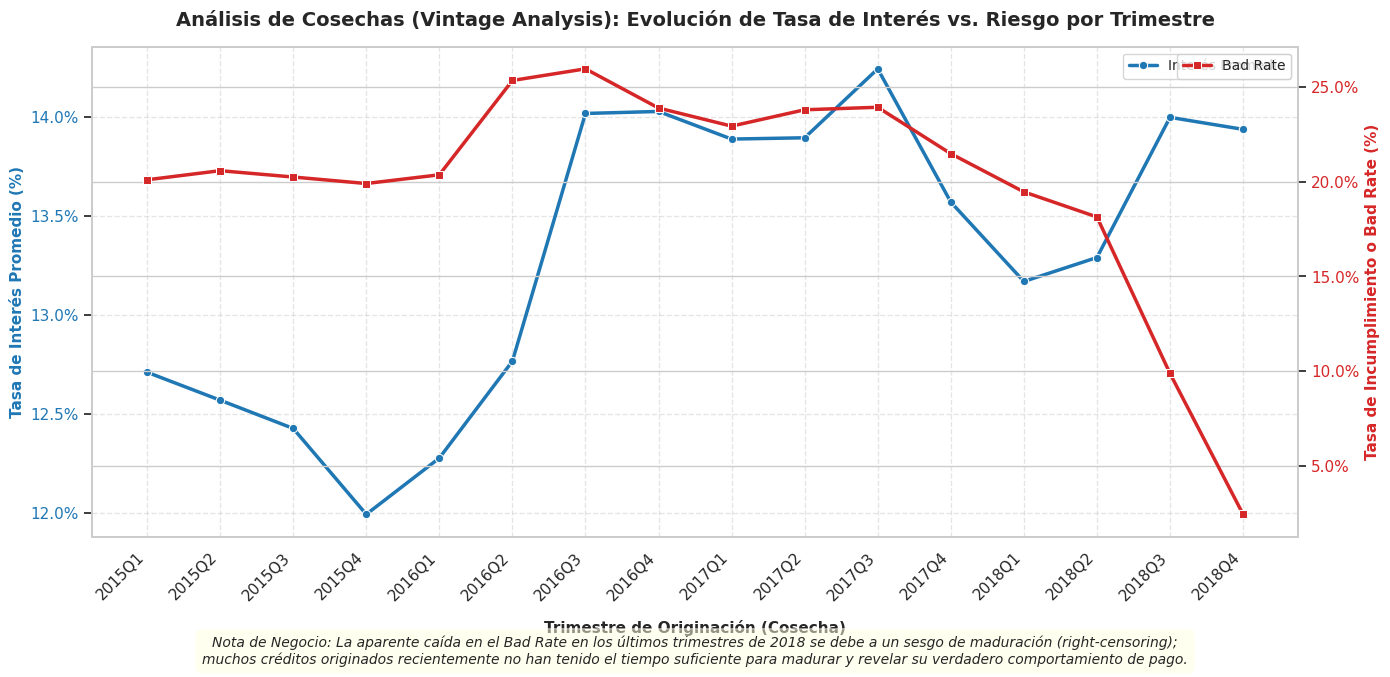

In [ ]:
print("Generando Análisis de Cosechas por Trimestre...")

# Crear el período trimestral para agrupar
df['issue_quarter'] = df['issue_d'].dt.to_period('Q')

vintage = df.groupby('issue_quarter').agg(
    volume_originated=('loan_amnt', 'sum'),
    loan_count=('loan_amnt', 'count'),
    bad_rate=('target', 'mean'),
    avg_int_rate=('int_rate', 'mean')
).reset_index()

vintage['issue_quarter_str'] = vintage['issue_quarter'].astype(str)

# Mostrar tabla consolidada de cosechas
display(vintage.head(16))

# Gráfica profesional de doble eje sin warnings de set_xticklabels
fig, ax1 = plt.subplots(figsize=(14, 7))

color_int = '#1f77b4' # Azul corporativo
ax1.set_xlabel('Trimestre de Originación (Cosecha)', fontweight='bold', labelpad=12)
ax1.set_ylabel('Tasa de Interés Promedio (%)', color=color_int, fontweight='bold')
sns.lineplot(x='issue_quarter_str', y='avg_int_rate', data=vintage, marker='o', sort=False, color=color_int, linewidth=2.5, ax=ax1, label='Interés Promedio')
ax1.tick_params(axis='y', labelcolor=color_int)
ax1.set_xticks(range(len(vintage)))
ax1.set_xticklabels(vintage['issue_quarter_str'], rotation=45, ha='right')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color_bad = '#d62728' # Rojo de alerta
ax2.set_ylabel('Tasa de Incumplimiento o Bad Rate (%)', color=color_bad, fontweight='bold')
sns.lineplot(x='issue_quarter_str', y='bad_rate', data=vintage, marker='s', sort=False, color=color_bad, linewidth=2.5, ax=ax2, label='Bad Rate')
ax2.tick_params(axis='y', labelcolor=color_bad)

# Formatear ejes como porcentajes
import matplotlib.ticker as mtick
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
# bad_rate es una proporción (0.0 a 1.0), por lo que usamos max_value=1.0
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))

# Agregar nota de negocio relevante (Sesgo de Maduración / Right-Censoring)
plt.text(0.5, -0.26,
         "Nota de Negocio: La aparente caída en el Bad Rate en los últimos trimestres de 2018 se debe a un sesgo de maduración (right-censoring);\n"
         "muchos créditos originados recientemente no han tenido el tiempo suficiente para madurar y revelar su verdadero comportamiento de pago.",
         transform=ax1.transAxes, fontsize=10, style='italic', bbox=dict(facecolor='lightyellow', alpha=0.5, boxstyle='round,pad=0.5'), ha='center')

plt.title('Análisis de Cosechas (Vintage Analysis): Evolución de Tasa de Interés vs. Riesgo por Trimestre', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

# Sección 3: Modelado Predictivo Out-of-Time (Benchmark vs. LightGBM)

Set de Entrenamiento (Pre-2017-07-01): 759998 registros
Set de Prueba Out-of-Time (Post-2017-07-01): 134253 registros
Entrenando modelo de Regresión Logística (Benchmark)...
Entrenando modelo LightGBM (Principal)...
[LightGBM] [Info] Number of positive: 165379, number of negative: 594619
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.080377 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3117
[LightGBM] [Info] Number of data points in the train set: 759998, number of used features: 90
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.217605 -> initscore=-1.279681
[LightGBM] [Info] Start training from score -1.279681


,Métrica,Regresión Logística (Benchmark),LightGBM (Modelo Principal)
0,AUC-ROC (Discriminación),0.707299,0.714723
1,PR-AUC (Precisión-Recall),0.354211,0.372216
2,Estadístico KS,0.302355,0.311044


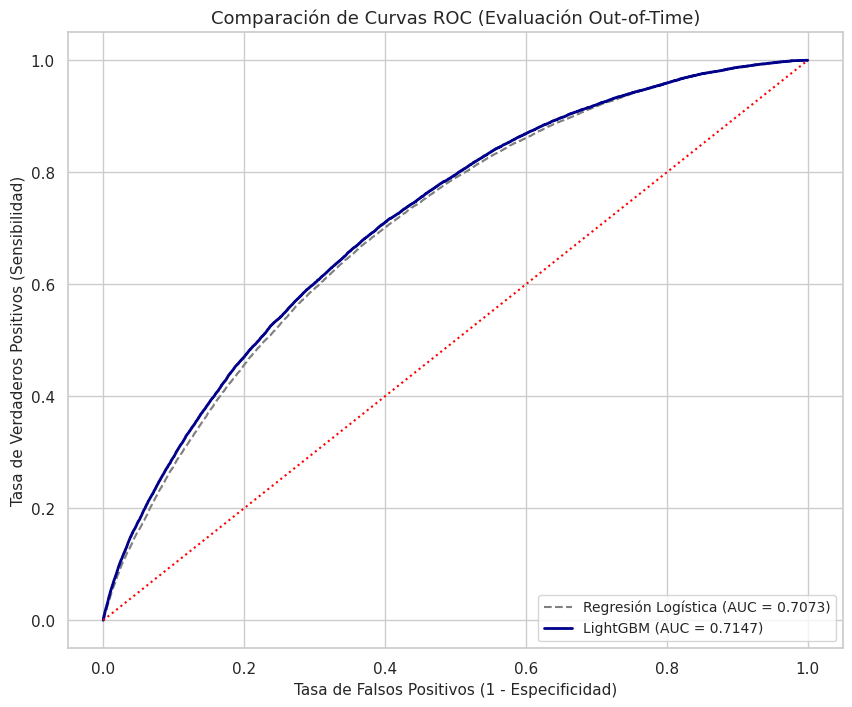

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve

# 1. Definición de variables
numeric_features = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs',
    'credit_history_months', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
    'total_acc', 'debt_to_income_monthly', 'loan_to_income', 'revol_bal_to_income'
]

categorical_features = [
    'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose'
]

# Partición Out-of-Time para simular una implementación en producción real
split_date = '2017-07-01'

train_set = df[df['issue_d'] < split_date].copy()
test_set = df[df['issue_d'] >= split_date].copy()

X_train, y_train = train_set[numeric_features + categorical_features], train_set['target']
X_test, y_test = test_set[numeric_features + categorical_features], test_set['target']

print(f"Set de Entrenamiento (Pre-{split_date}): {X_train.shape[0]} registros")
print(f"Set de Prueba Out-of-Time (Post-{split_date}): {X_test.shape[0]} registros")

# 2. Construcción de Pipelines de Preprocesamiento
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 3. Pipelines de Modelado
pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=500, random_state=42))
])

pipe_lgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(random_state=42, n_jobs=-1, n_estimators=150, learning_rate=0.05))
])

# Entrenar modelos
print("Entrenando modelo de Regresión Logística (Benchmark)...")
pipe_lr.fit(X_train, y_train)

print("Entrenando modelo LightGBM (Principal)...")
pipe_lgb.fit(X_train, y_train)

# 4. Evaluación del Modelo
y_pred_lr = pipe_lr.predict_proba(X_test)[:, 1]
y_pred_lgb = pipe_lgb.predict_proba(X_test)[:, 1]

# Calcular métricas
auc_lr = roc_auc_score(y_test, y_pred_lr)
auc_lgb = roc_auc_score(y_test, y_pred_lgb)

precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_pred_lr)
pr_auc_lr = auc(recall_lr, precision_lr)

precision_lgb, recall_lgb, _ = precision_recall_curve(y_test, y_pred_lgb)
pr_auc_lgb = auc(recall_lgb, precision_lgb)

def calculate_ks(y_true, y_probs):
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    ks = max(tpr - fpr)
    return ks, fpr, tpr

ks_lr, fpr_lr, tpr_lr = calculate_ks(y_test, y_pred_lr)
ks_lgb, fpr_lgb, tpr_lgb = calculate_ks(y_test, y_pred_lgb)

# Presentar métricas en un DataFrame claro
metrics_summary = pd.DataFrame({
    'Métrica': ['AUC-ROC (Discriminación)', 'PR-AUC (Precisión-Recall)', 'Estadístico KS'],
    'Regresión Logística (Benchmark)': [auc_lr, pr_auc_lr, ks_lr],
    'LightGBM (Modelo Principal)': [auc_lgb, pr_auc_lgb, ks_lgb]
})

display(metrics_summary)

# Graficar Curvas ROC Comparativas
plt.figure(figsize=(10, 8))
plt.plot(fpr_lr, tpr_lr, label=f'Regresión Logística (AUC = {auc_lr:.4f})', color='grey', linestyle='--')
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {auc_lgb:.4f})', color='darkblue', linewidth=2)
plt.plot([0, 1], [0, 1], color='red', linestyle=':')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.title('Comparación de Curvas ROC (Evaluación Out-of-Time)')
plt.legend(loc='lower right')
plt.show()

# Sección 4: Explicabilidad del Modelo (SHAP Values)

Calculando valores SHAP con TreeExplainer...
Generando Gráfico Beeswarm Global...


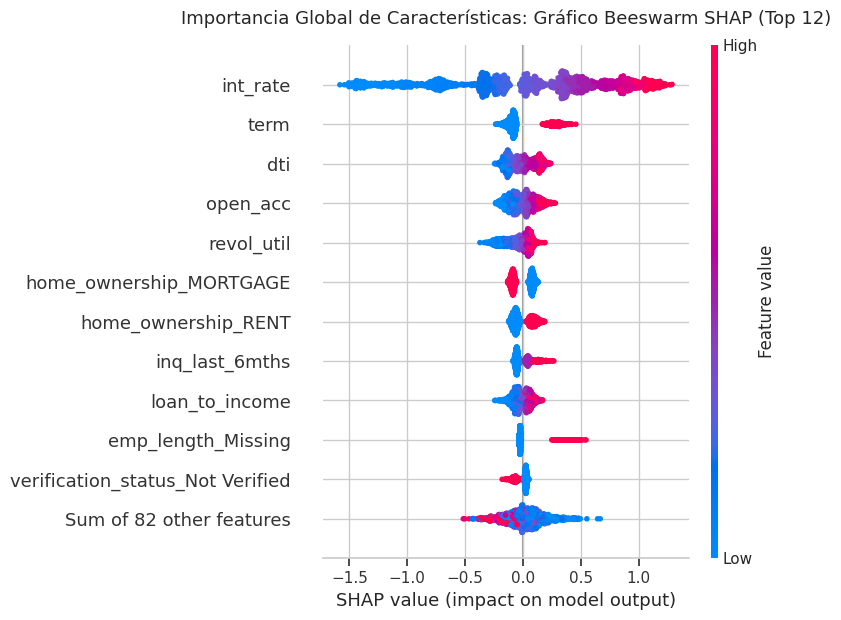

Generando Waterfall para el Cliente con Menor Probabilidad de Default...


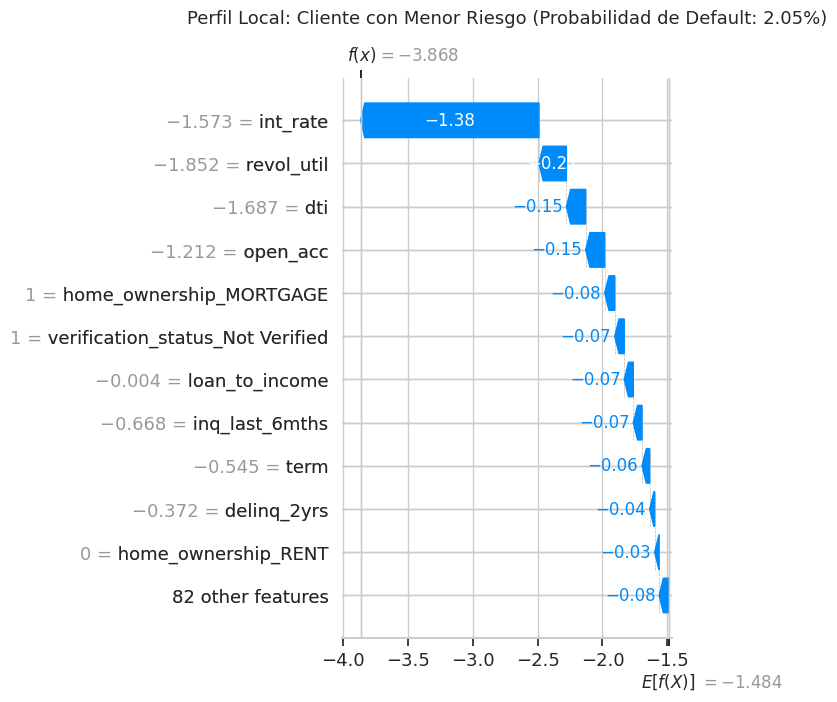

Generando Waterfall para el Cliente con Mayor Probabilidad de Default...


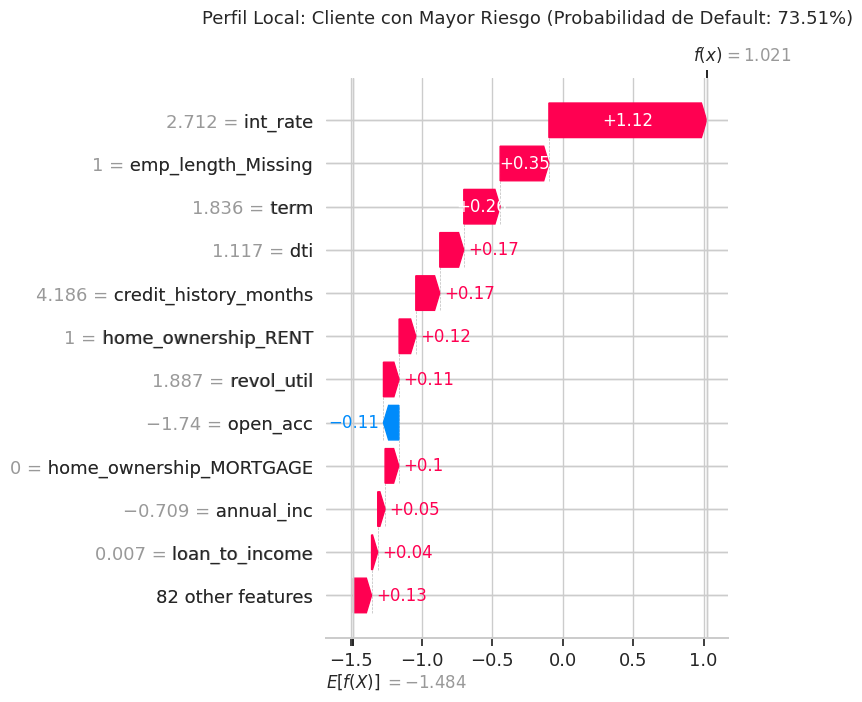

In [ ]:
!pip install shap -q
import shap

print("Calculando valores SHAP con TreeExplainer...")
# Extraer preprocesador y modelo entrenado
preprocessor_fit = pipe_lgb.named_steps['preprocessor']
model_lgb = pipe_lgb.named_steps['classifier']

# Obtener nombres de columnas transformadas
cat_encoder = preprocessor_fit.named_transformers_['cat'].named_steps['onehot']
cat_cols = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_transformed_cols = numeric_features + cat_cols

# Transformar una muestra del set de prueba para agilizar el cómputo de SHAP
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=2000, replace=False)
X_test_sample = X_test.loc[sample_indices]
y_test_sample = y_test.loc[sample_indices]

X_test_sample_transformed = preprocessor_fit.transform(X_test_sample)
if hasattr(X_test_sample_transformed, 'toarray'):
    X_test_sample_transformed = X_test_sample_transformed.toarray()

X_test_sample_df = pd.DataFrame(X_test_sample_transformed, columns=all_transformed_cols, index=sample_indices)

# Inicializar TreeExplainer sobre el modelo LightGBM entrenado
explainer = shap.TreeExplainer(model_lgb)
shap_values = explainer(X_test_sample_df)

# 1. Gráfico Global: Summary Beeswarm Plot (Top 12)
print("Generando Gráfico Beeswarm Global...")
plt.figure(figsize=(12, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title('Importancia Global de Características: Gráfico Beeswarm SHAP (Top 12)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# Calcular probabilidades para identificar extremos en la muestra
probs_sample = pipe_lgb.predict_proba(X_test_sample)[:, 1]
min_pd_idx = np.argmin(probs_sample)
max_pd_idx = np.argmax(probs_sample)

# 2. Explicabilidad Local: Waterfall para el cliente con menor probabilidad de default
print("Generando Waterfall para el Cliente con Menor Probabilidad de Default...")
plt.figure() # Inicializa una figura limpia
shap.plots.waterfall(shap_values[min_pd_idx], max_display=12, show=False)
plt.title(f'Perfil Local: Cliente con Menor Riesgo (Probabilidad de Default: {probs_sample[min_pd_idx]:.2%})', fontsize=13, pad=15)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
plt.close() # Cierra la figura activa

# 3. Explicabilidad Local: Waterfall para el cliente con mayor probabilidad de default
print("Generando Waterfall para el Cliente con Mayor Probabilidad de Default...")
plt.figure() # Inicializa una figura limpia
shap.plots.waterfall(shap_values[max_pd_idx], max_display=12, show=False)
plt.title(f'Perfil Local: Cliente con Mayor Riesgo (Probabilidad de Default: {probs_sample[max_pd_idx]:.2%})', fontsize=13, pad=15)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
plt.close() # Cierra la figura activa

# Sección 5: Optimización Financiera de Utilidad Neta (P&L)

Simulando optimización financiera calibrada de la cartera...

      RESUMEN EJECUTIVO: OPTIMIZACIÓN DE RENTABILIDAD DE PORTAFOLIO
Estrategia Pasiva (Aprobar 100% de Clientes):
 - Tasa de Aprobación:       100.00%
 - Bad Rate del Portafolio:  19.87%
 - Utilidad Neta Total:      $-15,431,093.58 USD
---------------------------------------------------------------------------
Estrategia Óptima con LightGBM (Umbral Máximo PD: 28.50%):
 - Tasa de Aprobación Óptima:70.38%
 - Bad Rate bajo Control:    13.35%
 - Utilidad Neta Maximizada: $-2,858,422.62 USD
---------------------------------------------------------------------------
IMPACTO FINANCIERO DEL MODELO:
 - Mejora Neta en Utilidad:  +$12,572,670.96 USD (+81.48%)



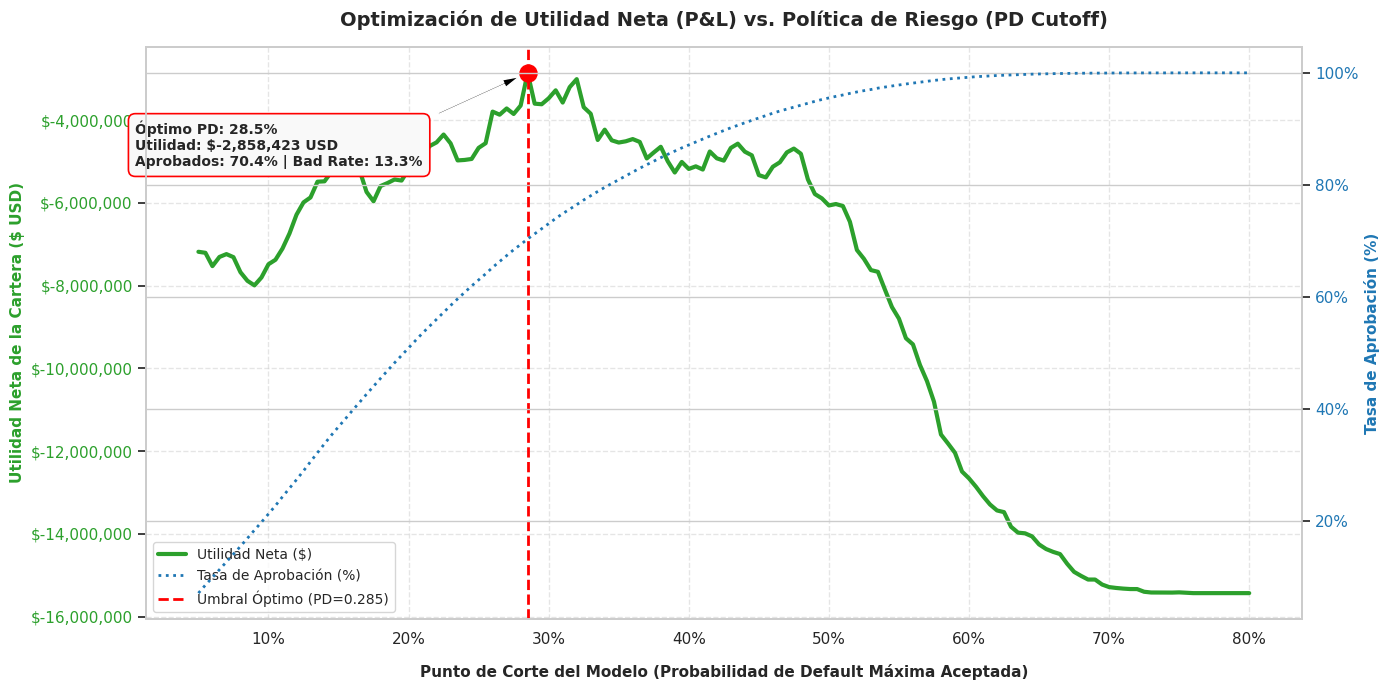

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

print("Simulando optimización financiera calibrada de la cartera...")

# 1. Preparación de datos financieros de test
df_finance = X_test.copy()
df_finance['target'] = y_test
df_finance['y_pred_proba'] = y_pred_lgb

# 2. Definición del cálculo de P&L individual por préstamo según fórmula requerida
def calculate_portfolio_pnl_recalibrated(df_portfolio, threshold):
    """
    Simula el impacto de negocio según un umbral de aceptación basado en PD (threshold).
    """
    # Dividir deudores según decisión de riesgo (aprobados vs rechazados)
    aprobados = df_portfolio[df_portfolio['y_pred_proba'] <= threshold].copy()
    no_aprobados = df_portfolio[df_portfolio['y_pred_proba'] > threshold].copy()

    total_customers = len(df_portfolio)
    num_aprobados = len(aprobados)
    pct_aprobacion = num_aprobados / total_customers if total_customers > 0 else 0
    bad_rate = aprobados['target'].mean() if num_aprobados > 0 else 0

    # Calcular P&L individual para deudores aprobados
    if num_aprobados > 0:
        pnl_buenos = (
            aprobados['loan_amnt'] * (aprobados['int_rate'] / 100) * (aprobados['term'] / 12) * 0.58
        ) + (aprobados['loan_amnt'] * 0.02) - (aprobados['loan_amnt'] * 0.06 * (aprobados['term'] / 12) * 0.58) - 50

        pnl_malos = - (aprobados['loan_amnt'] * 0.70) + (aprobados['loan_amnt'] * 0.02) - 50

        # Aplicar condicional según target (0 = pagó, 1 = incumplió)
        real_pnl = np.where(aprobados['target'] == 0, pnl_buenos, pnl_malos)
        utilidad_aprobados = real_pnl.sum()
    else:
        utilidad_aprobados = 0.0

    # Costo operativo fijo aplicado a los rechazados (50 por solicitud procesada)
    utilidad_rechazados = - (len(no_aprobados) * 50)

    total_net_utility = utilidad_aprobados + utilidad_rechazados

    return {
        'threshold': threshold,
        'pct_aprobacion': pct_aprobacion,
        'bad_rate': bad_rate,
        'utilidad_neta': total_net_utility
    }

# 3. Simulación de umbrales finos (pasos de 0.005)
thresholds_range = np.arange(0.05, 0.805, 0.005)
sim_results = []

for t in thresholds_range:
    sim_results.append(calculate_portfolio_pnl_recalibrated(df_finance, t))

df_sim_results = pd.DataFrame(sim_results)

# 4. Encontrar punto óptimo
opt_idx = df_sim_results['utilidad_neta'].idxmax()
opt_threshold = df_sim_results.loc[opt_idx, 'threshold']
opt_aprobacion = df_sim_results.loc[opt_idx, 'pct_aprobacion']
opt_bad_rate = df_sim_results.loc[opt_idx, 'bad_rate']
opt_utilidad = df_sim_results.loc[opt_idx, 'utilidad_neta']

# Estrategia Pasiva (Aprobar el 100% de las solicitudes, threshold = 1.0)
res_todos = calculate_portfolio_pnl_recalibrated(df_finance, 1.0)
utilidad_todos = res_todos['utilidad_neta']
bad_rate_todos = res_todos['bad_rate']

incremento_usd = opt_utilidad - utilidad_todos
incremento_pct = (incremento_usd / abs(utilidad_todos)) * 100 if utilidad_todos != 0 else 0

# --- Imprimir Reporte de Resumen Ejecutivo ---
print("\n" + "="*75)
print("      RESUMEN EJECUTIVO: OPTIMIZACIÓN DE RENTABILIDAD DE PORTAFOLIO")
print("="*75)
print(f"Estrategia Pasiva (Aprobar 100% de Clientes):")
print(f" - Tasa de Aprobación:       100.00%")
print(f" - Bad Rate del Portafolio:  {bad_rate_todos:.2%}")
print(f" - Utilidad Neta Total:      ${utilidad_todos:,.2f} USD")
print("-" * 75)
print(f"Estrategia Óptima con LightGBM (Umbral Máximo PD: {opt_threshold:.2%}):")
print(f" - Tasa de Aprobación Óptima:{opt_aprobacion:.2%}")
print(f" - Bad Rate bajo Control:    {opt_bad_rate:.2%}")
print(f" - Utilidad Neta Maximizada: ${opt_utilidad:,.2f} USD")
print("-" * 75)
print(f"IMPACTO FINANCIERO DEL MODELO:")
print(f" - Mejora Neta en Utilidad:  +${incremento_usd:,.2f} USD (+{incremento_pct:.2f}%)")
print("="*75 + "\n")

# --- Graficar Curva de Doble Eje (Utilidad vs Tasa de Aprobación) ---
fig, ax1 = plt.subplots(figsize=(14, 7))

# Eje izquierdo (Utilidad Neta en USD)
color_util = '#2ca02c'
ax1.set_xlabel('Punto de Corte del Modelo (Probabilidad de Default Máxima Aceptada)', fontweight='bold', labelpad=12)
ax1.set_ylabel('Utilidad Neta de la Cartera ($ USD)', color=color_util, fontweight='bold')
line_util = ax1.plot(df_sim_results['threshold'], df_sim_results['utilidad_neta'], color=color_util, linewidth=3, label='Utilidad Neta ($)')
ax1.tick_params(axis='y', labelcolor=color_util)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax1.grid(True, linestyle='--', alpha=0.5)

# Eje derecho (Tasa de Aprobación en %)
ax2 = ax1.twinx()
color_aprob = '#1f77b4'
ax2.set_ylabel('Tasa de Aprobación (%)', color=color_aprob, fontweight='bold')
line_aprob = ax2.plot(df_sim_results['threshold'], df_sim_results['pct_aprobacion'], color=color_aprob, linewidth=2, linestyle=':', label='Tasa de Aprobación (%)')
ax2.tick_params(axis='y', labelcolor=color_aprob)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# Línea roja vertical en el óptimo de utilidad
line_opt = ax1.axvline(x=opt_threshold, color='red', linestyle='--', linewidth=2, label=f'Umbral Óptimo (PD={opt_threshold:.3f})')

# Resaltar punto óptimo
ax1.scatter(opt_threshold, opt_utilidad, color='red', s=150, zorder=5)

# Caja de anotación para el Punto Óptimo (Colocada a la izquierda de la línea vertical)
ax1.annotate(f'Óptimo PD: {opt_threshold:.1%}\n'
             f'Utilidad: ${opt_utilidad:,.0f} USD\n'
             f'Aprobados: {opt_aprobacion:.1%} | Bad Rate: {opt_bad_rate:.1%}',
             xy=(opt_threshold, opt_utilidad),
             xytext=(opt_threshold - 0.28, opt_utilidad - (df_sim_results['utilidad_neta'].max() - df_sim_results['utilidad_neta'].min()) * 0.18),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.2, headwidth=6),
             bbox=dict(boxstyle="round,pad=0.5", fc="#f9f9f9", ec="red", lw=1.2),
             fontsize=10, fontweight='bold')

# Combinar leyendas
lines = line_util + line_aprob + [line_opt]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left')

plt.title('Optimización de Utilidad Neta (P&L) vs. Política de Riesgo (PD Cutoff)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()